In [ ]:
import pandas as pd
import numpy as np
import warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

warnings.filterwarnings("ignore")

# Localizar la raíz del proyecto
PROJECT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed").is_dir()),
    None
)

if PROJECT_DIR is None:
    raise FileNotFoundError("No se encontró data/processed.")

DATA_DIR = PROJECT_DIR / "data" / "processed"

train = pd.read_csv(DATA_DIR / "ghi_multisitio_entrenamiento.csv")
validacion = pd.read_csv(DATA_DIR / "ghi_multisitio_validacion.csv")
test = pd.read_csv(DATA_DIR / "ghi_multisitio_prueba.csv")

print("Train:", train.shape)
print("Validación:", validacion.shape)
print("Test:", test.shape)

In [ ]:
#convertir fecha
for df in [train, validacion, test]:
    df["fecha_hora"] = pd.to_datetime(
        df["fecha_hora"],
        errors="coerce"
    )

In [ ]:
#crear la serie para SARIMA
train_sarima = (
    train[["fecha_hora", "comuna", "ghi"]]
    .dropna()
    .sort_values(["comuna", "fecha_hora"])
    .reset_index(drop=True)
)

validacion_sarima = (
    validacion[["fecha_hora", "comuna", "ghi"]]
    .dropna()
    .sort_values(["comuna", "fecha_hora"])
    .reset_index(drop=True)
)

test_sarima = (
    test[["fecha_hora", "comuna", "ghi"]]
    .dropna()
    .sort_values(["comuna", "fecha_hora"])
    .reset_index(drop=True)
)

In [ ]:
#verificar datos
for nombre, df in [
    ("Entrenamiento", train_sarima),
    ("Validación", validacion_sarima),
    ("Prueba", test_sarima)
]:
    print(f"\n{nombre}")

    for comuna, grupo in df.groupby("comuna"):
        print(
            comuna,
            "| registros:", len(grupo),
            "| periodo:", grupo["fecha_hora"].min(),
            "a", grupo["fecha_hora"].max()
        )


Entrenamiento
colchane | registros: 87648 | periodo: 2004-01-02 00:00:00 a 2013-12-31 23:00:00
pica | registros: 87648 | periodo: 2004-01-02 00:00:00 a 2013-12-31 23:00:00
pozo_almonte | registros: 87648 | periodo: 2004-01-02 00:00:00 a 2013-12-31 23:00:00

Validación
colchane | registros: 17520 | periodo: 2014-01-01 00:00:00 a 2015-12-31 23:00:00
pica | registros: 17520 | periodo: 2014-01-01 00:00:00 a 2015-12-31 23:00:00
pozo_almonte | registros: 17520 | periodo: 2014-01-01 00:00:00 a 2015-12-31 23:00:00

Prueba
colchane | registros: 8664 | periodo: 2016-01-01 00:00:00 a 2016-12-26 23:00:00
pica | registros: 8664 | periodo: 2016-01-01 00:00:00 a 2016-12-26 23:00:00
pozo_almonte | registros: 8664 | periodo: 2016-01-01 00:00:00 a 2016-12-26 23:00:00


In [ ]:
#definir configuraciones
configuraciones = [
    {
        "Configuración": "SARIMA 1",
        "order": (1, 0, 0),
        "seasonal_order": (1, 0, 0, 24)
    },
    {
        "Configuración": "SARIMA 2",
        "order": (1, 0, 1),
        "seasonal_order": (1, 0, 0, 24)
    }
]

In [ ]:
#evaluar en validación
import gc
import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

resultados_validacion_sarima = []
resultados_por_sitio = []

for config in configuraciones:

    reales_globales = []
    predicciones_globales = []

    print(f"\nEvaluando {config['Configuración']}")

    for comuna in sorted(train_sarima["comuna"].unique()):

        y_train = (
            train_sarima.loc[
                train_sarima["comuna"] == comuna,
                "ghi"
            ]
            .to_numpy(dtype="float64")
        )

        y_valid = (
            validacion_sarima.loc[
                validacion_sarima["comuna"] == comuna,
                "ghi"
            ]
            .to_numpy(dtype="float64")
        )

        modelo = SARIMAX(
            y_train,
            order=config["order"],
            seasonal_order=config["seasonal_order"],
            trend="c",
            enforce_stationarity=False,
            enforce_invertibility=False,
            concentrate_scale=True
        )

        # Ahorrar memoria, pero conservar los estados que necesita extend()
        modelo.ssm.set_conserve_memory(
            memory_no_forecast_cov=True,
            memory_no_filtered=True,
            memory_no_gain=True,
            memory_no_smoothing=True,
            memory_no_std_forecast=True
        )

        ajuste = modelo.fit(
            disp=False,
            maxiter=30,
            cov_type="none"
        )

        # Continuar la serie con los datos reales de validación
        ajuste_validacion = ajuste.extend(y_valid)

        pred_valid = np.asarray(
            ajuste_validacion.fittedvalues,
            dtype=float
        )

        pred_valid = np.clip(pred_valid, 0, None)

        mae = mean_absolute_error(y_valid, pred_valid)
        rmse = np.sqrt(mean_squared_error(y_valid, pred_valid))
        r2 = r2_score(y_valid, pred_valid)

        resultados_por_sitio.append({
            "Configuración": config["Configuración"],
            "Localidad": comuna,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        reales_globales.extend(y_valid)
        predicciones_globales.extend(pred_valid)

        print(
            comuna,
            "| MAE:", round(mae, 2),
            "| RMSE:", round(rmse, 2)
        )

        # Liberar memoria antes de pasar al siguiente sitio
        del modelo
        del ajuste
        del ajuste_validacion
        del y_train
        del y_valid
        del pred_valid

        gc.collect()

    resultados_validacion_sarima.append({
        "Configuración": config["Configuración"],
        "Orden": str(config["order"]),
        "Orden estacional": str(config["seasonal_order"]),
        "MAE": mean_absolute_error(
            reales_globales,
            predicciones_globales
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                reales_globales,
                predicciones_globales
            )
        ),
        "R2": r2_score(
            reales_globales,
            predicciones_globales
        )
    })

    del reales_globales
    del predicciones_globales
    gc.collect()


Evaluando SARIMA 1
colchane | MAE: 55.0 | RMSE: 113.19
pica | MAE: 29.13 | RMSE: 71.43
pozo_almonte | MAE: 26.64 | RMSE: 69.98

Evaluando SARIMA 2
colchane | MAE: 54.25 | RMSE: 113.14
pica | MAE: 29.06 | RMSE: 71.36
pozo_almonte | MAE: 26.14 | RMSE: 70.07


In [ ]:
#mostrar en tabla
tabla_validacion_sarima = pd.DataFrame(
    resultados_validacion_sarima
).sort_values("MAE")

tabla_sarima_por_sitio = pd.DataFrame(
    resultados_por_sitio
)

display(tabla_validacion_sarima)
display(tabla_sarima_por_sitio)

,Configuración,Orden,Orden estacional,MAE,RMSE,R2
1,SARIMA 2,"(1, 0, 1)","(1, 0, 0, 24)",36.482829,87.183778,0.949925
0,SARIMA 1,"(1, 0, 0)","(1, 0, 0, 24)",36.923790,87.197958,0.949909


,Configuración,Localidad,MAE,RMSE,R2
0,SARIMA 1,colchane,55.003143,113.186740,0.919917
1,SARIMA 1,pica,29.133116,71.431599,0.965574
2,SARIMA 1,pozo_almonte,26.635110,69.976710,0.966728
3,SARIMA 2,colchane,54.249394,113.143490,0.919979
4,SARIMA 2,pica,29.062731,71.356528,0.965646
5,SARIMA 2,pozo_almonte,26.136362,70.070180,0.966639


In [ ]:
#prueba final
import gc

config_final = {
    "order": (1, 0, 0),
    "seasonal_order": (1, 0, 0, 24)
}

train_final_sarima = pd.concat(
    [train_sarima, validacion_sarima],
    ignore_index=True
).sort_values(["comuna", "fecha_hora"])

resultados_test_sarima = []

for comuna in sorted(train_final_sarima["comuna"].unique()):

    y_train_final = train_final_sarima.loc[
        train_final_sarima["comuna"] == comuna,
        "ghi"
    ].to_numpy(dtype=float)

    grupo_test = (
        test_sarima[test_sarima["comuna"] == comuna]
        .sort_values("fecha_hora")
        .reset_index(drop=True)
    )

    y_test_local = grupo_test["ghi"].to_numpy(dtype=float)

    modelo = SARIMAX(
        y_train_final,
        order=config_final["order"],
        seasonal_order=config_final["seasonal_order"],
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False,
        concentrate_scale=True
    )

    modelo.ssm.set_conserve_memory(
        memory_no_forecast_cov=True,
        memory_no_filtered=True,
        memory_no_gain=True,
        memory_no_smoothing=True,
        memory_no_std_forecast=True
    )

    ajuste = modelo.fit(
        disp=False,
        maxiter=30,
        cov_type="none"
    )

    extension = ajuste.extend(y_test_local)

    predicciones = np.asarray(
        extension.fittedvalues,
        dtype=float
    )

    # Se elimina la primera observación para evaluar
    # exactamente el pronóstico de la hora siguiente
    reales = y_test_local[1:]
    predicciones = np.clip(predicciones[1:], 0, None)
    fechas = grupo_test["fecha_hora"].iloc[1:].to_numpy()

    for fecha, real, prediccion in zip(
        fechas,
        reales,
        predicciones
    ):
        resultados_test_sarima.append({
            "fecha_hora": fecha,
            "comuna": comuna,
            "ghi_real": real,
            "ghi_pronosticado": prediccion
        })

    del modelo, ajuste, extension
    gc.collect()

resultados_test_sarima = pd.DataFrame(
    resultados_test_sarima
)

print(resultados_test_sarima.shape)
display(resultados_test_sarima.head())

(25989, 4)


,fecha_hora,comuna,ghi_real,ghi_pronosticado
0,2016-01-01 01:00:00,colchane,0.0,18.847915
1,2016-01-01 02:00:00,colchane,0.0,18.847915
2,2016-01-01 03:00:00,colchane,0.0,18.847915
3,2016-01-01 04:00:00,colchane,0.0,18.847915
4,2016-01-01 05:00:00,colchane,0.0,18.847915


In [ ]:
mae_sarima = mean_absolute_error(
    resultados_test_sarima["ghi_real"],
    resultados_test_sarima["ghi_pronosticado"]
)

rmse_sarima = np.sqrt(
    mean_squared_error(
        resultados_test_sarima["ghi_real"],
        resultados_test_sarima["ghi_pronosticado"]
    )
)

r2_sarima = r2_score(
    resultados_test_sarima["ghi_real"],
    resultados_test_sarima["ghi_pronosticado"]
)

print("SARIMA FINAL")
print(f"MAE:  {mae_sarima:.4f} W/m²")
print(f"RMSE: {rmse_sarima:.4f} W/m²")
print(f"R²:   {r2_sarima:.4f}")

SARIMA FINAL
MAE:  31.8380 W/m²
RMSE: 73.8855 W/m²
R²:   0.9649


In [ ]:
metricas_sarima_localidad = []

for comuna, grupo in resultados_test_sarima.groupby("comuna"):

    metricas_sarima_localidad.append({
        "Localidad": comuna,
        "MAE": mean_absolute_error(
            grupo["ghi_real"],
            grupo["ghi_pronosticado"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                grupo["ghi_real"],
                grupo["ghi_pronosticado"]
            )
        ),
        "R2": r2_score(
            grupo["ghi_real"],
            grupo["ghi_pronosticado"]
        )
    })

metricas_sarima_localidad = pd.DataFrame(
    metricas_sarima_localidad
)

display(metricas_sarima_localidad)

,Localidad,MAE,RMSE,R2
0,colchane,47.661776,96.880626,0.943163
1,pica,24.424215,57.266920,0.978461
2,pozo_almonte,23.427930,60.925024,0.975130


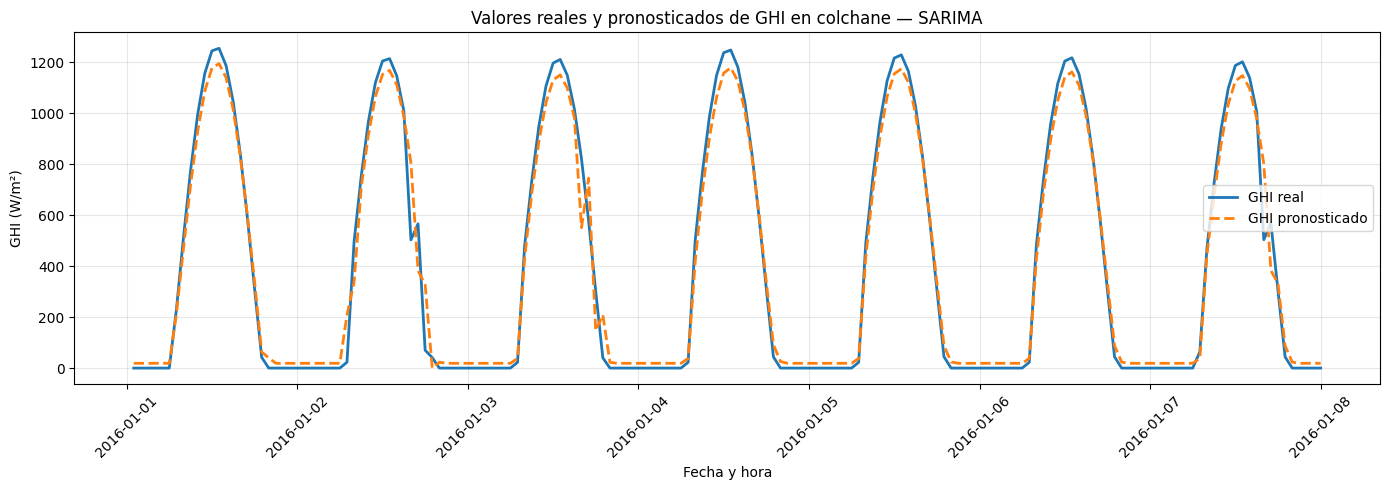

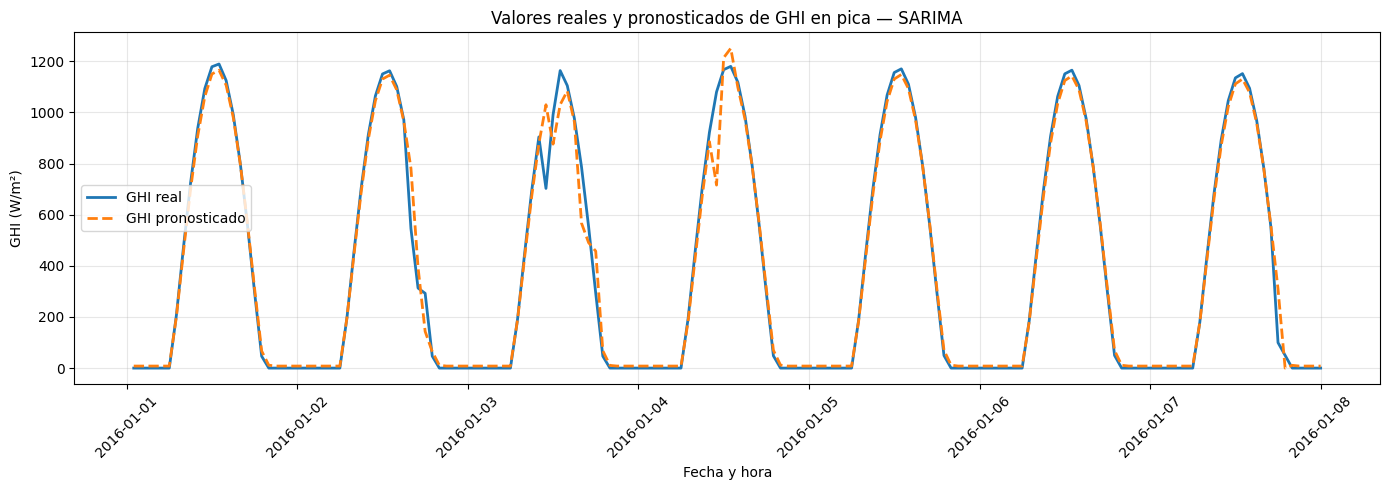

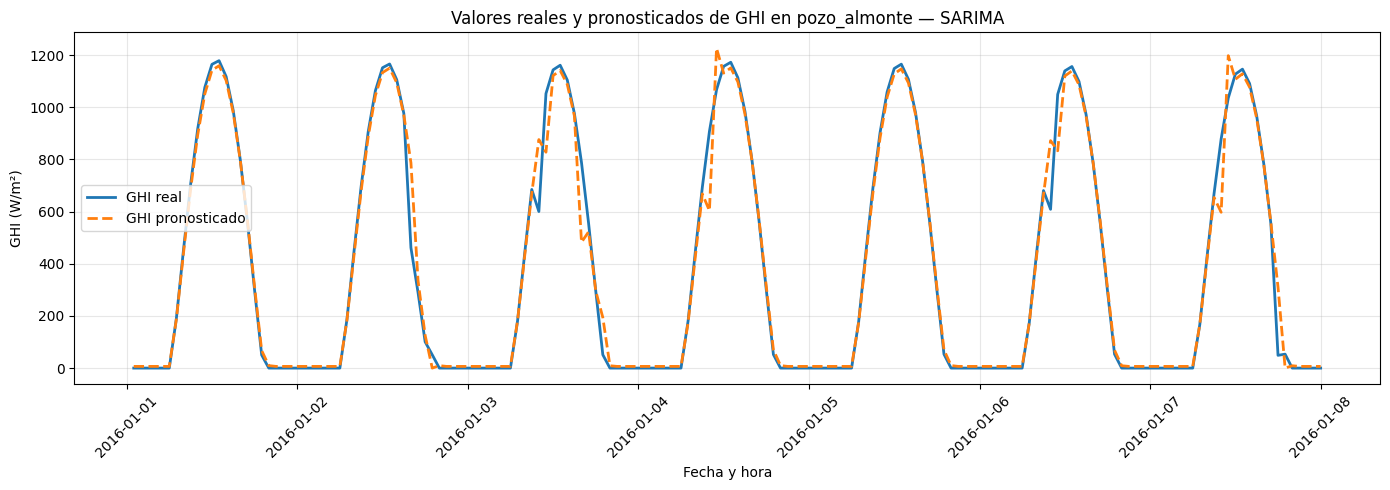

In [ ]:
#graficos
import matplotlib.pyplot as plt

FIGURES_DIR = PROJECT_DIR / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

for comuna in resultados_test_sarima["comuna"].unique():

    muestra = (
        resultados_test_sarima[
            resultados_test_sarima["comuna"] == comuna
        ]
        .sort_values("fecha_hora")
        .head(24 * 7)
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        muestra["fecha_hora"],
        muestra["ghi_real"],
        label="GHI real",
        linewidth=2
    )

    plt.plot(
        muestra["fecha_hora"],
        muestra["ghi_pronosticado"],
        label="GHI pronosticado",
        linestyle="--",
        linewidth=2
    )

    plt.title(f"Valores reales y pronosticados de GHI en {comuna} — SARIMA")
    plt.xlabel("Fecha y hora")
    plt.ylabel("GHI (W/m²)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()


    plt.savefig(
        FIGURES_DIR / f"sarima_real_vs_pronosticado_{comuna}.png",
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

In [ ]:
resultados_test_sarima["residuo"] = (
    resultados_test_sarima["ghi_real"]
    - resultados_test_sarima["ghi_pronosticado"]
)

print(
    "Media de residuos:",
    resultados_test_sarima["residuo"].mean()
)

print(
    "Desviación estándar:",
    resultados_test_sarima["residuo"].std()
)

Media de residuos: -0.13015461538804335
Desviación estándar: 73.88683626586194
